# Instagram Engagement Analysis and Audience Growth Optimization

**Exploratory Data Analysis and Visualization (EDAV) Project**

Investigating the multidimensional determinants of Instagram reach and engagement across media formats, scheduling windows, and hashtag density.

- **Metric**: Engagement Rate = $(Likes + Comments) / Views \times 100$
- **Dataset**: 600 post records across 5 creator accounts (Fit, Food, Tech, Trip, Meme) spanning Jan–Oct 2024.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Plot styling
sns.set_theme(style="whitegrid", palette="deep", font_scale=0.95)
pd.options.display.float_format = "{:,.2f}".format
rng = np.random.default_rng(11)
order = ["Reel", "Carousel", "Photo", "Video"]
pal = dict(zip(order, sns.color_palette("deep", 4)))

## 1. Data Ingestion and Simulation

Simulating 600 publication records across 5 creator accounts with calibrated log-normal reach distributions and algorithmic multipliers.

In [ ]:
n = 600
users = np.array(["Fit", "Food", "Tech", "Trip", "Meme"])
kinds = np.array(["Reel", "Photo", "Video", "Carousel"])

uid = rng.integers(0, 5, n)
kid = rng.choice(4, n, p=[0.45, 0.20, 0.10, 0.25])
hour = rng.integers(6, 24, n)
tags = rng.integers(0, 26, n)
date = np.sort(rng.choice(pd.date_range("2024-01-01", periods=305).to_numpy(), n))
dow = pd.DatetimeIndex(date).dayofweek

# Baseline reach per creator tier with log-normal noise
reach = np.array([12e3, 45e3, 80e3, 150e3, 300e3])[uid] * rng.lognormal(-1.6, 0.7, n)

# Format, temporal, and hashtag boosters
boost = (
    np.array([2.4, 0.9, 1.2, 1.1])[kid]
    * (1 + 0.5 * np.exp(-(hour - 20) ** 2 / 18))       # Evening peak curve
    * (1 + 0.6 * np.exp(-(tags - 10) ** 2 / 50))       # ~10-15 hashtag sweet spot
    * np.where(dow >= 5, 1.15, 1.0)                    # Weekend boost
)

views = (reach * boost).astype(int)
likes = (views * np.array([0.05, 0.06, 0.045, 0.09])[kid] * (1 + 0.12 * np.exp(-(hour - 20) ** 2 / 18)) * rng.uniform(0.7, 1.3, n)).astype(int)
comments = (likes * rng.uniform(0.02, 0.10, n) * np.where(dow >= 5, 1.3, 1.0)).astype(int)

# Introduce missing hour flags to simulate data quality imperfections
hour[rng.choice(n, 10, replace=False)] = -1

df = pd.DataFrame({
    "date": date, "user": users[uid], "kind": kinds[kid],
    "hour": hour, "tags": tags, "views": views,
    "likes": likes, "comments": comments
})
print(f"Generated {len(df)} records across {df['user'].nunique()} accounts.")
df.head()

Generated 600 records across 5 accounts.


## 2. Data Cleaning and Feature Engineering

- Imputing corrupted hours (`-1`) with format-specific medians.
- Deriving Engagement Rate ($ER\%$), Time Slots, Reach Tiers, and Hashtag Bins.

In [ ]:
# Impute missing hours
df['hour'] = df['hour'].replace(-1, np.nan)
df['hour'] = df.groupby('kind')['hour'].transform(lambda x: x.fillna(x.median())).astype(int)

# Feature engineering
df['eng'] = (df['likes'] + df['comments']) / df['views'] * 100
df['slot'] = pd.cut(df['hour'], [5, 12, 17, 24], labels=['morning', 'afternoon', 'evening'])
df['tier'] = pd.cut(df['views'], [0, 5e3, 5e4, np.inf], labels=['low', 'mid', 'high'])
df['tag_bin'] = pd.cut(df['tags'], [-1, 5, 10, 15, 20, 25], labels=['0-5', '6-10', '11-15', '16-20', '21-25'])
df['lift'] = df['views'] / df.groupby(['user', 'kind'], observed=True)['views'].transform('median')
df['kind'] = pd.Categorical(df['kind'], categories=order, ordered=True)

# Time series dataframe indexed by date
ts = df.set_index('date').sort_index()
print("Missing values after cleaning:", df.isna().sum().to_dict())
df[['views', 'likes', 'comments', 'tags', 'eng']].describe()

Missing values after cleaning: {'date': 0, 'user': 0, 'kind': 0, 'hour': 0, 'tags': 0, 'views': 0, 'likes': 0, 'comments': 0, 'eng': 0, 'slot': 0, 'tier': 0, 'tag_bin': 0, 'lift': 0}


## 3. Exploratory Data Analysis & Distributions

Examining engagement rate distributions, views density, and metric relationships.

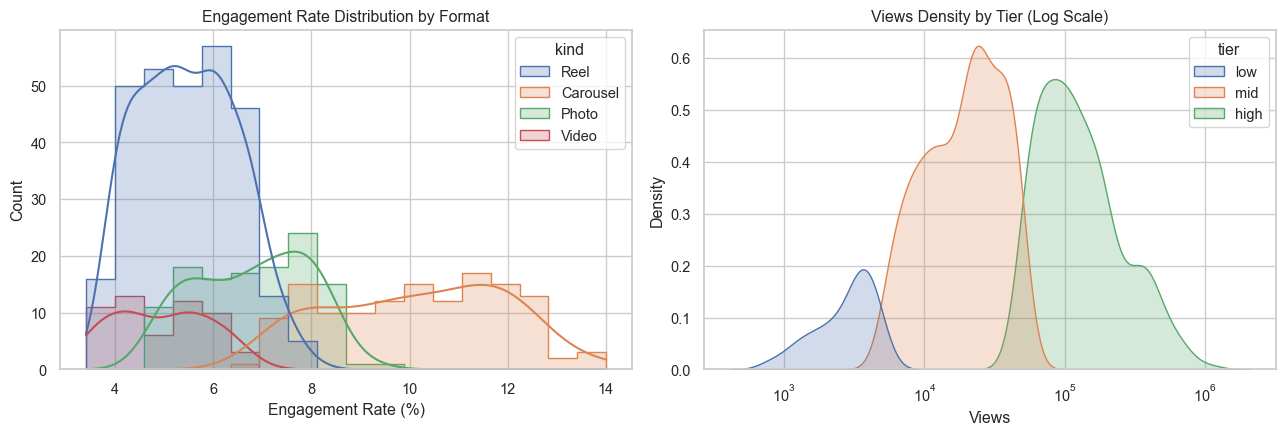

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="eng", hue="kind", hue_order=order, palette=pal, kde=True, element="step", ax=ax[0])
ax[0].set(title="Engagement Rate Distribution by Format", xlabel="Engagement Rate (%)")

sns.kdeplot(data=df, x="views", hue="tier", hue_order=["low", "mid", "high"], log_scale=True, fill=True, ax=ax[1])
ax[1].set(title="Views Density by Tier (Log Scale)", xlabel="Views")
plt.tight_layout()
plt.show()

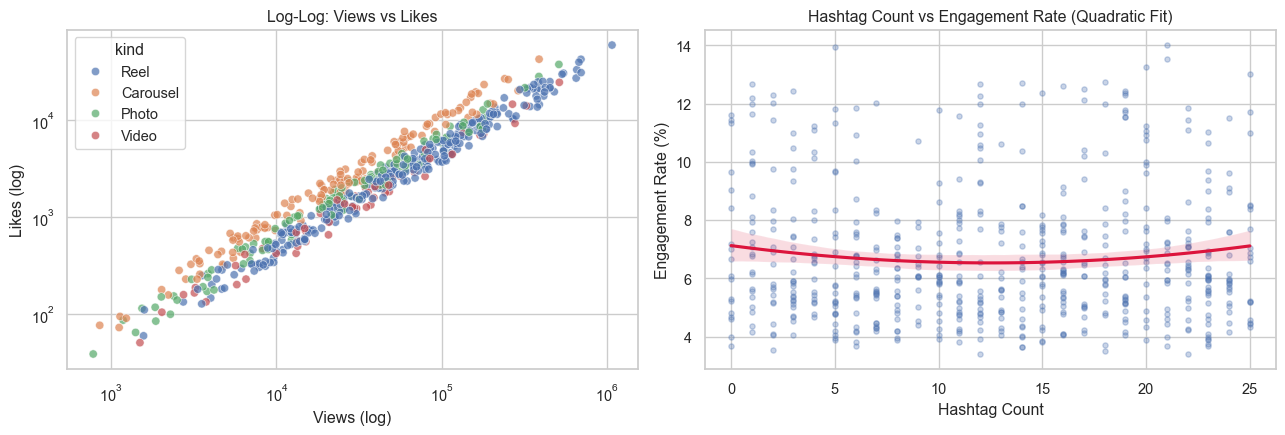

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="views", y="likes", hue="kind", hue_order=order, palette=pal, alpha=0.7, ax=ax[0])
ax[0].set(xscale="log", yscale="log", title="Log-Log: Views vs Likes", xlabel="Views (log)", ylabel="Likes (log)")

sns.regplot(data=df, x="tags", y="eng", order=2, scatter_kws={"alpha": 0.3, "s": 14}, line_kws={"color": "crimson"}, ax=ax[1])
ax[1].set(title="Hashtag Count vs Engagement Rate (Quadratic Fit)", xlabel="Hashtag Count", ylabel="Engagement Rate (%)")
plt.tight_layout()
plt.show()

## 4. Longitudinal & Temporal Visualization

Tracking cumulative views by format, monthly engagement trends, and 7-day rolling patterns.

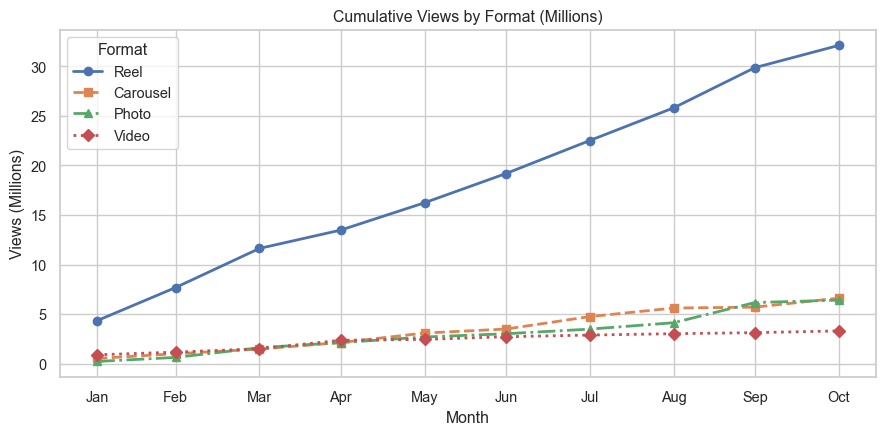

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for kd, ls, mk in zip(order, ["-", "--", "-.", ":"], ["o", "s", "^", "D"]):
    c = ts[ts.kind == kd].views.resample("ME").sum().cumsum() / 1e6
    ax.plot(c.index, c.values, ls=ls, marker=mk, lw=2, color=pal[kd], label=kd)
ax.set_xticks(c.index)
ax.set_xticklabels(c.index.strftime("%b"), rotation=0)
ax.set(title="Cumulative Views by Format (Millions)", xlabel="Month", ylabel="Views (Millions)")
ax.legend(title="Format")
plt.tight_layout()
plt.show()

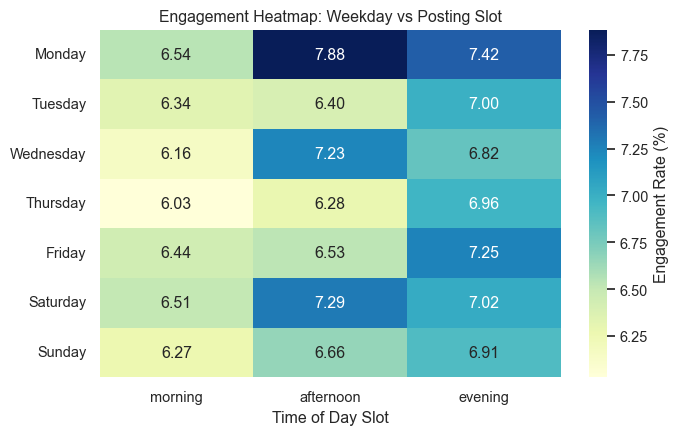

In [ ]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hm = ts.pivot_table(index=ts.index.day_name(), columns="slot", values="eng").reindex(index=days, columns=["morning", "afternoon", "evening"])

plt.figure(figsize=(7, 4.5))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Engagement Rate (%)"})
plt.title("Engagement Heatmap: Weekday vs Posting Slot")
plt.ylabel("")
plt.xlabel("Time of Day Slot")
plt.tight_layout()
plt.show()

## 5. Research Questions & Decision Framework

Addressing the core research questions: format reach vs engagement trade-off, hashtag sweet spot, scheduling matrix, breakout posts, and format scorecard.

In [ ]:
# Helper functions for analysis
def best_hours(kind, n=3):
    return df[df.kind == kind].groupby('hour').eng.mean().nlargest(n)

def top(kind=None, user=None, n=5, by='views'):
    d = df if kind is None else df[df.kind == kind]
    d = d if user is None else d[d.user == user]
    return d.nlargest(n, by)[['date', 'user', 'kind', 'hour', 'tags', 'views', 'eng']]

# Question 1: Format Scorecard
s = df.groupby('kind', observed=True).agg(
    posts=('eng', 'size'),
    med_views=('views', 'median'),
    med_likes=('likes', 'median'),
    eng=('eng', 'mean')
)
s['best_hour'] = [best_hours(k, 1).index[0] for k in s.index]
display(s.style.format({'med_views': '{:,.0f}', 'med_likes': '{:,.0f}', 'eng': '{:.2f}%'}).set_caption('Media Format Scorecard'))

 posts med_views med_likes eng best_hour
kind     
Reel 290 58,141 2,974 5.48% 21
Carousel 134 24,377 2,280 10.16% 6
Photo 121 25,288 1,767 6.79% 21
Video 55 29,752 1,334 4.94% 14



In [ ]:
# Question 2: Hashtag Sweet Spot
tb = df.groupby('tag_bin', observed=True).agg(
    posts=('eng', 'size'),
    med_views=('views', 'median'),
    eng=('eng', 'mean')
)
display(tb.style.format({'med_views': '{:,.0f}', 'eng': '{:.2f}%'}).set_caption('Hashtag Density Bins'))

 posts med_views eng
tag_bin   
0-5 134 44,866 7.04%
6-10 108 38,764 6.22%
11-15 120 48,300 6.57%
16-20 121 35,802 7.12%
21-25 117 24,824 6.65%



In [ ]:
# Question 3: Best Posting Hours Matrix
best_hrs_df = pd.DataFrame({k: best_hours(k).index.tolist() for k in order}, index=["1st", "2nd", "3rd"]).rename_axis("Rank Priority")
display(best_hrs_df)

               Reel  Carousel  Photo  Video
Rank Priority                              
1st              21         6     21     14
2nd              20        20     20     17
3rd              18        22     18     21


In [ ]:
# Question 4: Algorithmic Breakout Posts (Views > 3x Median)
bo = df[df.lift > 3]
print(f"{len(bo)} Breakout Posts ({len(bo)/len(df):.1%} of all posts) detected:")
display(bo.nlargest(5, 'lift')[['date', 'user', 'kind', 'hour', 'views', 'lift']])
display(bo['kind'].value_counts(normalize=True).to_frame('Share of Breakouts').style.format('{:.1%}'))

32 Breakout Posts (5.3% of all posts) detected:
          date  user   kind  hour    views  lift
417 2024-08-03  Tech   Reel    23   674302 11.16
10  2024-01-06  Tech   Reel    22   413001  6.83
197 2024-04-16   Fit  Photo    22    23506  6.11
163 2024-03-30  Meme   Reel    12  1068132  5.32
121 2024-03-04   Fit  Photo    18    20028  5.20
 Share of Breakouts
kind 
Reel 56.2%
Photo 21.9%
Carousel 12.5%
Video 9.4%



In [ ]:
# Question 5: Month-over-Month Growth Trajectory
mo = ts.resample('ME').agg(posts=('views', 'size'), views=('views', 'sum'), eng=('eng', 'mean'))
mo['growth'] = mo['views'].pct_change()
mo.index = mo.index.strftime('%b %Y')
display(mo.style.format({'views': '{:,.0f}', 'eng': '{:.2f}%', 'growth': '{:+.1%}'}, na_rep='-').set_caption('Month-Over-Month Performance'))

 posts views eng growth
date    
Jan 2024 60 5,963,294 6.27% -
Feb 2024 54 4,500,798 6.55% -24.5%
Mar 2024 56 5,738,695 6.92% +27.5%
Apr 2024 51 3,878,318 6.97% -32.4%
May 2024 64 4,372,210 7.13% +12.7%
Jun 2024 60 3,942,230 6.47% -9.8%
Jul 2024 65 5,226,662 6.80% +32.6%
Aug 2024 60 4,943,917 6.70% -5.4%
Sep 2024 73 6,292,343 6.59% +27.3%
Oct 2024 57 3,570,533 7.06% -43.3%



## 6. Summary Findings and Strategic Insights

In [ ]:
sl = df.groupby('slot').eng.mean()
wd = ts.groupby(ts.index.day_name()).eng.mean()

print(f"Best format by reach      : {s.med_views.idxmax()} ({s.med_views.max():,.0f} median views)")
print(f"Best format by engagement : {s.eng.idxmax()} ({s.eng.max():.2f}% mean engagement)")
print(f"Hashtag sweet spot        : {tb.med_views.idxmax()} hashtags ({tb.loc[tb.med_views.idxmax(), 'med_views']:,.0f} median views)")
print(f"Best time to post         : {wd.idxmax()} {sl.idxmax()} ({sl.max():.2f}% slot engagement)")
print(f"Breakout posts            : {len(bo)} total ({bo.kind.value_counts().idxmax()} captures {bo.kind.value_counts(normalize=True).max():.1%})")

Best format by reach      : Reel (58,141 median views)
Best format by engagement : Carousel (10.16% mean engagement)
Hashtag sweet spot        : 11-15 hashtags (48,300 median views)
Best time to post         : Monday evening (7.04% slot engagement)
Breakout posts            : 32 total (Reel captures 56.2%)
